In [44]:
import os
from pathlib import Path
import pandas as pd
import librosa

import numpy as np
from numpy import ndarray
import random
import scipy
import scipy.signal
from scipy.stats import skew, kurtosis

import matplotlib.pyplot as plt
import glob
from tqdm import tqdm
import pyworld as pw
import pysptk

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

from IPython.display import display, Audio

from lazypredict.Supervised import LazyClassifier
from sklearn.model_selection import train_test_split 
import copy 

from pysptk.synthesis import AllPoleDF
from pysptk.synthesis import Synthesizer

import torch
import torchaudio

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Define the model part using lazypredict


In [3]:
def classifing_lazypredict(data_train, data_test, feat_names, label_name):

    clf = LazyClassifier(verbose=0, ignore_warnings=True, custom_metric=None)
    X_train = data_train[feat_names].to_numpy()
    X_test = data_test[feat_names].to_numpy()
    y_train = data_train[label_name].to_numpy()
    y_test = data_test[label_name].to_numpy()
    _, metrics = clf.fit(X_train, X_test, y_train, y_test);
    
    model_dictionary = clf.provide_models(X_train, X_test, y_train, y_test)
    return model_dictionary, metrics

# Common functions

## Data I/O

In [4]:
def load_audio(audio_path):
    return librosa.load(audio_path, sr=None)
    

class STFTWindowParams:
    def __init__(self, sample_rate=16000, win_sec=0.032, hop_sec=0.016):
        self.sample_rate = sample_rate
        self.win_sec = win_sec
        self.hop_sec = hop_sec

        self.update()

    def update(self):
        self.win_size = int(self.win_sec * self.sample_rate)
        self.hop_size = int(self.hop_sec * self.sample_rate)
        self.fft_size = self.next_pow_2(self.win_size)

    @staticmethod
    def next_pow_2(x):
        return 2 ** (x - 1).bit_length()

## Feature Extraction

In [5]:
def feat_pipeline(file_list, mod_extraction, mod_manipulation, feat_name, debug=None):

    rows = []
    total = len(file_list)
        
    for cnt, i in tqdm(enumerate(file_list), total=len(file_list)):
        x, sr = load_audio(i)
        feat = mod_extraction(x)

        if mod_manipulation is not None:
            feat = mod_manipulation(feat)
           
        rows.append({
            "name": str(i.name),
            "{:s}".format(feat_name): feat,
        })
    
        if debug is not None and cnt >= debug:
            break
            
    dataframe = pd.DataFrame(rows)
    return dataframe

# Fundamental frequency (F0)

## F0 Inconsistency / Monotonic Pitch
**Target system**: Concatenative TTS / some TTS that flatten pitch  
**Feature**: F0 trajectory  
**Manipulations**:  
  
- F0 segment shifting (Incons.)  
- F0 segment shuffling (Incons.)  
- F0 flattening (Monot.)  

### Extraction

In [6]:
def extract_f0(waveform,
              fs, win_size, hop_size,
              fmin: int = 70, fmax: int = 400) -> ndarray:

    x = np.copy(waveform)
    x = librosa.effects.preemphasis(x)
    autocorr_win_len = win_size // 2

    f0_freqs, _, _ = librosa.pyin(
        x, sr=fs,
        frame_length=win_size, hop_length=hop_size, center=True,
        win_length=autocorr_win_len, fmin=fmin, fmax=fmax, n_thresholds=7
    )

    # pyworld_analysis
    #x = np.array(x, dtype=np.float64)
    #_f0, t = pw.dio(x, sr)    # raw pitch extractor
    #f0_freqs = pw.stonemask(x, _f0, t, sr)  # pitch refinement
    
    return f0_freqs

### Manipulation

In [7]:
def f0_segment_shift(f0_traj, seg_len_s, hop_s, p_seg):
    f0_mod = f0_traj.copy()
    voiced = ~np.isnan(f0_mod)

    seg_len_frames = int(seg_len_s / hop_s)
    i = 0

    while i < len(f0_mod):
        if not voiced[i]:
            i += 1
            continue

        # find voiced segment f0_mod[seg_start : seg_end]
        seg_start = i
        while i < len(f0_mod) and voiced[i]:
            i += 1
        seg_end = i

        # chunk the voiced segment in pseudo-phonemes, shift some
        j = seg_start
        while j < seg_end:
            seg_j_end = min(j + seg_len_frames, seg_end)

            if np.random.rand() < p_seg:
                shift = random.choice([
                    random.uniform(0.87, 0.92),
                    random.uniform(1.08, 1.3)
                ])
                f0_mod[j:seg_j_end] *= shift

            j = seg_j_end

    return f0_mod


def f0_segment_shuffle(f0_traj, seg_len_s, hop_s, p_shuffle):
    f0_mod = f0_traj.copy()
    voiced = ~np.isnan(f0_mod)

    seg_len_frames = int(seg_len_s / hop_s)

    segments = []
    indices = []

    i = 0
    while i < len(f0_mod):
        if not voiced[i]:
            i += 1
            continue
        
        # find voiced segment f0_mod[seg_start : seg_end]
        seg_start = i
        while i < len(f0_mod) and voiced[i]:
            i += 1
        seg_end = i

        # chunk the voiced segment in pseudo-phonemes    
        j = seg_start
        while j < seg_end:
            seg_j_end = min(j + seg_len_frames, seg_end)
            
            segments.append(f0_mod[j:seg_j_end].copy())
            indices.append((j, seg_j_end))
            j = seg_j_end

    if len(segments) < 2:
        return f0_mod

    # partial shuffle
    perm = list(range(len(segments)))
    for i in range(len(perm)):
        if random.random() < p_shuffle:
            j = random.randrange(len(perm))
            perm[i], perm[j] = perm[j], perm[i]
            
    # re-insert
    for out_i, src_i in enumerate(perm):
        start, end = indices[out_i]
        seg = segments[src_i]
        L = min(end - start, len(seg))
        f0_mod[start:start + L] = seg[:L]
    
    return f0_mod        


def flatten_f0(f0_traj, strength=0.9, p=0.5):

    f0_mod = f0_traj.copy()
    voiced = ~np.isnan(f0_mod)

    f0_ref = np.nanmedian(f0_mod)
    mask = (np.random.rand(len(f0_mod)) < p) & voiced

    f0_mod[mask] = (
        (1.0 - strength) * f0_mod[mask]
        + strength * f0_ref
    )

    return f0_mod


def apply_f0_mod(f0_traj, mod='shift', hop_s=0.016):
    
    if mod == 'shift':
        seg_len = random.uniform(0.08, 0.16)  # 80–160 ms
        p_seg = random.uniform(0.4, 0.7)

        f0_traj_mod = f0_segment_shift(
            f0_traj,
            seg_len_s=seg_len,
            hop_s=hop_s,
            p_seg=p_seg
        )
        
    elif mod == 'shuff':
        seg_len = random.uniform(0.08, 0.16)
        p_shuffle = random.uniform(0.2, 0.5)

        f0_traj_mod = f0_segment_shuffle(
            f0_traj,
            seg_len_s=seg_len,
            hop_s=hop_s,
            p_shuffle=p_shuffle
        )
        
    elif mod == 'flat':
        f0_traj_mod = flatten_f0(
            f0_traj,
            strength=0.5,
            p=1
        )
        
    else:
        f0_traj_mod = None
        print("Manipulation not recognized.")
        
    return f0_traj_mod

### Case study

In [30]:
# ======================
# DATA CONFIG
# ======================

protocol_path = '/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.train.trn.txt'
audio_root = '/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_train/flac'

target_algorithm = 'A04'   
#target_algorithm = 'A02'

sample_num = 100

stft_params = STFTWindowParams()

In [31]:
def load_asvspoof_lists(protocol_path, audio_root, target_algorithm):
    
    df_all = pd.read_csv(protocol_path, sep=' ', header=None)

    # FAKE (specific algorithm)
    df_fake = (
        df_all[df_all[3] == target_algorithm]
        .assign(path=lambda df: df[1].apply(
            lambda x: Path(audio_root) / f"{x}.flac"
        ))[['path']]
    )
    fake_list = df_fake['path'].tolist()

    # REAL (bonafide)
    df_real = (
        df_all[df_all[4] == 'bonafide']
        .assign(path=lambda df: df[1].apply(
            lambda x: Path(audio_root) / f"{x}.flac"
        ))[['path']]
    )
    real_list = df_real['path'].tolist()

    return real_list, fake_list


real_list, fake_list = load_asvspoof_lists(
    protocol_path,
    audio_root,
    target_algorithm
)

print("Real:", len(real_list))
print("Fake:", len(fake_list))


Real: 2580
Fake: 3800


In [32]:
# WRAPPERS:

def f0_extraction(wav, stft_params=stft_params):
    f0_traj = extract_f0(
        wav,
        fs=stft_params.sample_rate,
        win_size=stft_params.win_size,
        hop_size=stft_params.hop_size
    )
    return f0_traj

def f0_manipulation(f0_traj, mode=None, stft_params=stft_params):
    if mode is None:
        return f0_traj

    return apply_f0_mod(
        f0_traj,
        mod=mode,
        hop_s=stft_params.hop_sec
    )

In [33]:
def build_dataset(
    real_list,
    fake_list,
    negative_modes=('shift', 'shuff'),
    feat_name='f0',
    sample_num=None
):
    # REAL (positive class)
    real_df = feat_pipeline(
        real_list,
        f0_extraction,
        None,
        feat_name=feat_name,
        debug=sample_num
    )
    real_df['label'] = 1

    # PROXY NEGATIVES (manipulated real)
    proxy_dfs = []

    for mode in negative_modes:
        df_mod = feat_pipeline(
            real_list,
            f0_extraction,
            lambda f0, m=mode: f0_manipulation(f0, m),
            feat_name=feat_name,
            debug=sample_num
        )
        df_mod['label'] = 0
        df_mod['proxy_type'] = mode
        proxy_dfs.append(df_mod)

    proxy_df = pd.concat(proxy_dfs, axis=0)

    # TRUE FAKE (evaluation only)
    fake_df = feat_pipeline(
        fake_list,
        f0_extraction,
        None,
        feat_name=feat_name,
        debug=sample_num
    )
    fake_df['label'] = 0
    fake_df['proxy_type'] = 'real_fake'

    return real_df, proxy_df, fake_df


In [34]:
def f0_scalar_features(
    f0,
    feature_set=None,
    max_lag=50,
    include_delta=True,
):
    if feature_set is None:
        feature_set = [
            "f0_range",
            "f0_var",
            "f0_std",
            "f0_ac_decay",
            "f0_skew",
            "f0_kurtosis",
            "df0_std",
            "df0_mean_abs",
            "df0_max_abs",
            "df0_skew"
        ]

    def autocorr_decay(x):
        x = x - np.mean(x)
        ac = np.correlate(x, x, mode='full')
        ac = ac[len(ac)//2:]
        ac /= ac[0] + 1e-8
        return np.mean(ac[1:max_lag])

    f0 = np.asarray(f0, dtype=float)
    voiced = ~np.isnan(f0)
    f0v = f0[voiced]

    if len(f0v) < 5:
        return None

    feats = {}

    if "f0_range" in feature_set:
        feats["f0_range"] = np.max(f0v) - np.min(f0v)

    if "f0_var" in feature_set:
        feats["f0_var"] = np.var(f0v)

    if "f0_std" in feature_set:
        feats["f0_std"] = np.std(f0v)

    if "f0_ac_decay" in feature_set:
        feats["f0_ac_decay"] = autocorr_decay(f0v)

    if "f0_skew" in feature_set:
        feats["f0_skew"] = skew(f0v)

    if "f0_kurtosis" in feature_set:
        feats["f0_kurtosis"] = kurtosis(f0v)

    if include_delta:
        df0 = np.diff(f0v)

        if "df0_std" in feature_set:
            feats["df0_std"] = np.std(df0)

        if "df0_mean_abs" in feature_set:
            feats["df0_mean_abs"] = np.mean(np.abs(df0))

        if "df0_max_abs" in feature_set:
            feats["df0_max_abs"] = np.max(np.abs(df0))

        if "df0_skew" in feature_set:
            feats["df0_skew"] = skew(df0)

    return feats

def make_feature_fn(feature_set, max_lag, include_delta):
    def feature_fn(f0):
        return f0_scalar_features(
            f0,
            feature_set=feature_set,
            max_lag=max_lag,
            include_delta=include_delta
        )
    return feature_fn

In [35]:
def preprocessing(data_frames, feature_fn):

    df = data_frames.copy()

    feature_dicts = df["f0"].apply(feature_fn)

    feature_df = feature_dicts.apply(
        lambda x: pd.Series(x) if x is not None else pd.Series(dtype=float)
    )

    df = pd.concat([df, feature_df], axis=1)
    feature_names = list(feature_df.columns)

    return df, feature_names


In [36]:
# Build raw F0 datasets
real_df, proxy_df, fake_df = build_dataset(
    real_list,
    fake_list,
    negative_modes=('shift', 'shuff'), 
    #negative_modes=('flat',),  # do not forget the comma at the end
    sample_num=sample_num
)

# Define scalar proxy configuration
feature_fn = make_feature_fn(
    #feature_set=["df0_mean_abs"],
    feature_set=None,
    max_lag=50,
    include_delta=True
)

# Apply scalar extraction
data_real, feat_names = preprocessing(real_df, feature_fn)
data_proxy, _ = preprocessing(proxy_df, feature_fn)
data_fake, _ = preprocessing(fake_df, feature_fn)


data_real_train, data_real_test = train_test_split(
    data_real,
    test_size=0.5,
    random_state=SEED
)
data_train = pd.concat([data_real_train, data_proxy], axis=0)
data_test = pd.concat([data_real_test, data_fake], axis=0)


model_dictionary, metrics = classifing_lazypredict(
    data_train,
    data_test,
    feat_names,
    'label'
)

100%|█████████████████████████████████████████████████████████████████████| 3800/3800 [22:52<00:00,  2.77it/s]


  0%|          | 0/32 [00:00<?, ?it/s]

[LightGBM] [Info] Number of positive: 1290, number of negative: 5160
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000759 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2550
[LightGBM] [Info] Number of data points in the train set: 6450, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.200000 -> initscore=-1.386294
[LightGBM] [Info] Start training from score -1.386294


In [37]:
metrics

,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Time Taken
Model,,,,,
PassiveAggressiveClassifier,0.66,0.62,0.62,0.67,0.03
LGBMClassifier,0.75,0.60,0.60,0.73,0.27
RandomForestClassifier,0.75,0.59,0.59,0.72,2.23
XGBClassifier,0.74,0.59,0.59,0.71,0.26
ExtraTreesClassifier,0.76,0.59,0.59,0.72,0.91
NearestCentroid,0.52,0.59,0.59,0.55,0.02
GaussianNB,0.54,0.58,0.58,0.57,0.02
BaggingClassifier,0.73,0.58,0.58,0.71,0.70
LogisticRegression,0.76,0.58,0.58,0.72,0.04


# Spectral domain

## Oversmoothing

### Extraction

In [16]:
def get_lsf(waveform, order=10, frame_length=400, hop_length=160):
    # Ensure waveform is float64 (standard for SPTK C-wrappers)
    waveform = waveform.astype(np.float64)
    
    # 1. Framing
    # Instead of util.frame, we'll use a list comprehension for reliability
    frames = [waveform[i:i + frame_length] for i in range(0, len(waveform) - frame_length, hop_length)]
    frames = np.stack(frames)
    
    # 2. Scipy Windowing
    # 'blackman' is standard, but 'hamming' or 'hann' are also common
    window = scipy.signal.get_window('blackman', frame_length, fftbins=False)
    windowed_frames = frames * window
    

    # 3. LPC Analysis
    # Note: lpc returns (order + 1) coefficients
    lpc_coeffs = pysptk.lpc(windowed_frames, order)

    # 4. Convert LPC to LSF
    try:
        # 2. Attempt conversion
        lsf = pysptk.lpc2lsp(lpc_coeffs)
        return lsf
    except RuntimeError:
        # 3. Fallback: If it fails, the filter was likely unstable.
        # We can 'stabilize' it by slightly moving roots inside the circle
        # (Often called bandwidth expansion)
        gamma = 0.9
        lpc_stable = lpc_coeffs * (gamma ** np.arange(lpc_coeffs.shape[1]))
        return pysptk.lpc2lsp(lpc_stable)
        
    return lsf

### Manipulation

In [17]:
def apply_lsf_mod(lsf, sigma=2.0):
    # We apply the filter along axis 0 (the temporal/frame axis)
    # This blurs the transition of each individual LSF over time
    smoothed_lsf = scipy.ndimage.gaussian_filter1d(lsf, sigma=sigma, axis=0)
    
    # Ensure the LSF ordering property is maintained (stability)
    # LSFs must be strictly increasing: 0 < w1 < w2 ... < pi
    smoothed_lsf = np.sort(smoothed_lsf, axis=1)
    
    return smoothed_lsf

### Case study

In [18]:
# WRAPPERS:

def lsf_extraction(wav, lsf_order=20, stft_params=stft_params):
    lsf_traj = get_lsf(
            wav + 1e-6 * np.random.randn(len(wav)),
            order= lsf_order,
            frame_length=stft_params.win_size, 
            hop_length=stft_params.hop_size     
        )
    
    return lsf_traj

def lsf_manipulation_smoothing(lsf_traj, stft_params=stft_params):
    return apply_lsf_mod(lsf_traj)

In [19]:
def build_lsf_dataset(
    real_list,
    fake_list,
    negative_modes=('smoothing',),
    feat_name='lsf',
    sample_num=None
):
    """
    negative_modes: list/tuple of manipulations to apply to REAL data
    """

    # ---- REAL (positive class) ----
    real_df = feat_pipeline(
        real_list,
        lsf_extraction,
        None,
        feat_name=feat_name,
        debug=sample_num
    )
    real_df['label'] = 1

    # ---- PROXY NEGATIVES ----
    proxy_dfs = []
    for mode in negative_modes:
        if mode == 'smoothing':  # extendable to other LSF manipulations
            mod_fn = lsf_manipulation_smoothing
        else:
            raise ValueError(f"Unknown LSF manipulation: {mode}")

        df_mod = feat_pipeline(
            real_list,
            lsf_extraction,
            mod_fn,
            feat_name=feat_name,
            debug=sample_num
        )
        df_mod['label'] = 0
        df_mod['proxy_type'] = mode
        proxy_dfs.append(df_mod)

    proxy_df = pd.concat(proxy_dfs, axis=0)

    # ---- TRUE FAKE ----
    fake_df = feat_pipeline(
        fake_list,
        lsf_extraction,
        None,
        feat_name=feat_name,
        debug=sample_num
    )
    fake_df['label'] = 0
    fake_df['proxy_type'] = 'real_fake'

    return real_df, proxy_df, fake_df


In [20]:
def preprocessing_lsf(data_frames, feat_name='lsf'):
    """
    Compute variance per LSF dimension
    """
    df = data_frames.copy()
    order = df.iloc[0][feat_name].shape[1]
    feat_names = []

    for i in range(order):
        col = f'lsp_gv_{i}'
        feat_names.append(col)
        df[col] = df[feat_name].apply(lambda x: x[:, i].std())

    return df, feat_names


In [21]:
sample_num = 100

# Build LSF datasets
real_df, proxy_df, fake_df = build_lsf_dataset(
    real_list,
    fake_list,
    negative_modes=('smoothing',),  # can add more manipulations here
    sample_num=sample_num
)

# Preprocess: compute variance features
data_real, feat_names = preprocessing_lsf(real_df)
data_proxy, _ = preprocessing_lsf(proxy_df)
data_fake, _ = preprocessing_lsf(fake_df)


  3%|█▊                                                                    | 100/3800 [00:09<05:39, 10.89it/s]


In [22]:
# Split REAL
data_real_train, data_real_test = train_test_split(
    data_real,
    test_size=0.5,
    random_state=SEED
)

# Build train/test
data_train = pd.concat([data_real_train, data_proxy], axis=0)
data_test = pd.concat([data_real_test, data_fake], axis=0)

# Train
model_dictionary, metrics = classifing_lazypredict(
    data_train,
    data_test,
    feat_names,
    'label'
)


  0%|          | 0/32 [00:00<?, ?it/s]

[LightGBM] [Info] Number of positive: 50, number of negative: 101
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000077 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1092
[LightGBM] [Info] Number of data points in the train set: 151, number of used features: 21
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.331126 -> initscore=-0.703098
[LightGBM] [Info] Start training from score -0.703098
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best

In [23]:
metrics


,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Time Taken
Model,,,,,
DecisionTreeClassifier,0.84,0.86,0.86,0.84,0.02
BaggingClassifier,0.83,0.86,0.86,0.83,0.04
XGBClassifier,0.83,0.85,0.85,0.83,0.03
LGBMClassifier,0.82,0.85,0.85,0.83,0.05
AdaBoostClassifier,0.76,0.81,0.81,0.77,0.14
QuadraticDiscriminantAnalysis,0.70,0.75,0.75,0.70,0.02
RandomForestClassifier,0.55,0.65,0.65,0.53,0.22
LinearDiscriminantAnalysis,0.43,0.55,0.55,0.38,0.02
RidgeClassifier,0.43,0.55,0.55,0.37,0.02


## Perfect silence

In [38]:
stft_params = STFTWindowParams()

In [39]:
def apply_db(spec):
    spec_db = torchaudio.functional.amplitude_to_DB(
        spec,
        multiplier=10.0,
        amin=1e-10,
        db_multiplier=0
    )
    return spec_db

### Extraction

In [40]:
def spec_extraction(y, stft_params=stft_params):

    spec_transform = torchaudio.transforms.Spectrogram(
        n_fft=stft_params.fft_size,
        hop_length=stft_params.hop_size,
        power=2
    )
    
    spec = spec_transform(torch.Tensor(y).unsqueeze(0))
    spec = spec.squeeze(0)

    spec_db = apply_db(spec)
    
    return spec_db

### Manipulation

In [50]:
def spec_manipulation(y, stft_params):
    """
    Compute a spectrogram from waveform y and zero out a time region directly in the waveform.
    90% of the time zeroing is at the end, 10% anywhere.
    """
    y = torch.tensor(y).float()
    n_samples = y.shape[-1] if y.dim() > 1 else y.shape[0]

    # Select time frames to zero
    spec_dummy = torchaudio.transforms.Spectrogram(
        n_fft=stft_params.fft_size,
        hop_length=stft_params.hop_size,
        power=2
    )(y.unsqueeze(0))  # just to get n_time
    n_time = spec_dummy.shape[-1]
    width = random.randint(10, 50)

    if random.random() < 0.9:
        # 90% at the end
        start_idx = max(n_time - width - random.randint(0, 5), 0)
    else:
        start_idx = random.randint(0, max(n_time - width, 0))
    end_idx = start_idx + width
    end_idx = min(end_idx, n_time)

    # Convert frame indices to sample indices
    hop_length = stft_params.hop_size
    fft_size = stft_params.fft_size

    start_sample = start_idx * hop_length
    end_sample = min(n_samples, (end_idx - 1) * hop_length + fft_size)

    y_zeroed = y.clone()
    y_zeroed[start_sample:end_sample] = 0.0

    
    spec_transform = torchaudio.transforms.Spectrogram(
        n_fft=fft_size,
        hop_length=hop_length,
        power=2
    )
    spec = spec_transform(y_zeroed.unsqueeze(0)).squeeze(0)
    spec_db = apply_db(spec)

    return spec_db


### Example

In [47]:
p = "/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.eval.trl.txt"
f = "/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_eval/flac"

df = pd.read_csv(p, sep=" ", header=None, names=["speaker_id", "audio_file", "-", "system_id", "key"])

bonafide_df = df[df['key'] == "bonafide"]
row = bonafide_df.iloc[0]      
audio_path = f + "/" + row.audio_file + ".flac"

In [52]:
y, sr = librosa.load(audio_path, sr=16000) 

zero_idx = 50
spec_db = spec_extraction(y, stft_params)
spec_db_zeroed = spec_manipulation(y, stft_params)


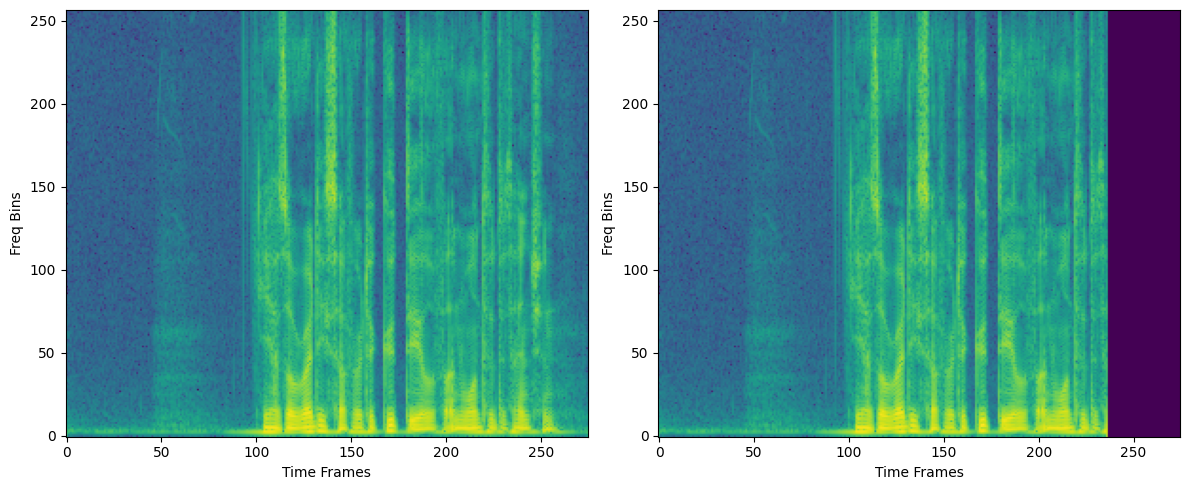

In [53]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(spec_db.numpy(), origin="lower", aspect="auto")
plt.xlabel("Time Frames")
plt.ylabel("Freq Bins")

plt.subplot(1, 2, 2)
plt.imshow(spec_db_zeroed.numpy(), origin="lower", aspect="auto")
plt.xlabel("Time Frames")
plt.ylabel("Freq Bins")

plt.tight_layout()
plt.show()